Image loaded! Processing 547x365 pixels manually. This might take a moment...
Processing complete! Generating visualizations...


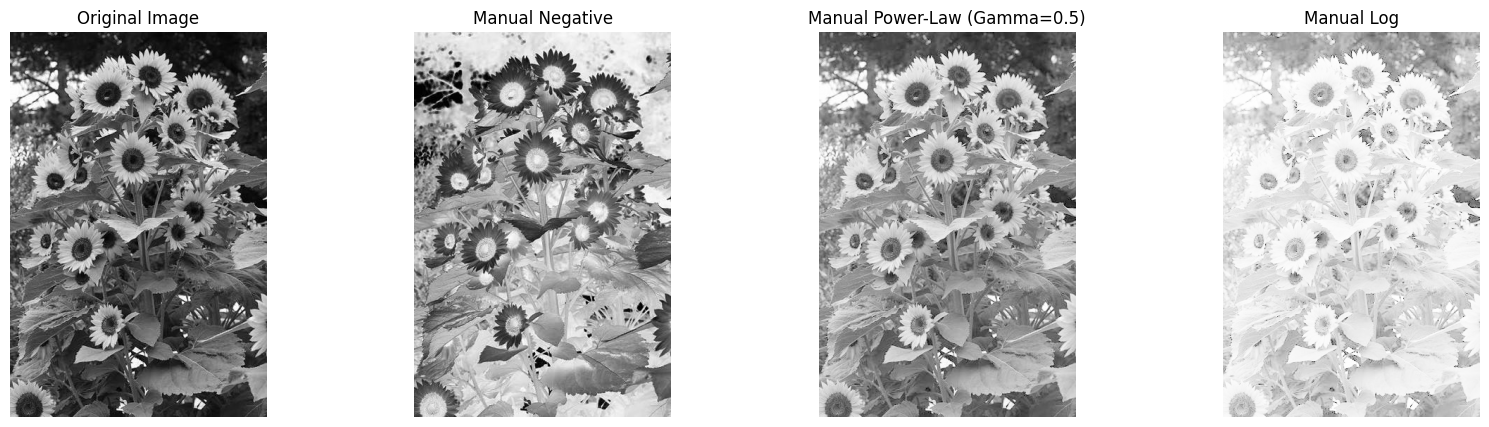

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. MANUAL MATH HELPERS (No built-in math functions)
# ==========================================

def manual_ln(x, terms=25):
    """Computes natural logarithm ln(x) manually using Taylor Series."""
    if x <= 0:
        return 0.0
    z = (x - 1) / (x + 1)
    z_squared = z * z
    current_term = z
    result = 0.0
    for n in range(terms):
        result += current_term / (2 * n + 1)
        current_term *= z_squared
    return 2 * result

def clamp_to_uint8(val):
    """Ensures pixel values stay safely between 0 and 255."""
    if val > 255: return 255
    if val < 0: return 0
    return int(val)

# ==========================================
# 2. FILE INPUT
# ==========================================

# Replace "image_19e003.jpg" with your actual filename if needed
image_path = "sunflower.jpg"

# Use OpenCV ONLY to read the JPEG compression and get a grayscale array
img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img_array is None:
    print(f"Error: Could not load '{image_path}'. Please check the file name.")
else:
    # Convert the NumPy array into a standard Python 2D list
    matrix = img_array.tolist()
    rows = len(matrix)
    cols = len(matrix[0])
    max_intensity = 255

    print(f"Image loaded! Processing {rows}x{cols} pixels manually. This might take a moment...")

    # ==========================================
    # 3. MANUAL TRANSFORMATIONS (Pure Python Loops)
    # ==========================================

    # --- A. Negative Transformation ---
    neg_matrix = []
    for r in range(rows):
        new_row = []
        for c in range(cols):
            new_row.append(max_intensity - matrix[r][c])
        neg_matrix.append(new_row)

    # --- B. Power-Law (Gamma) Transformation ---
    gamma = 0.5 # Change this to lighten (<1) or darken (>1)
    pow_matrix = []
    for r in range(rows):
        new_row = []
        for c in range(cols):
            r_norm = matrix[r][c] / max_intensity
            s_norm = r_norm ** gamma
            new_row.append(clamp_to_uint8(s_norm * max_intensity))
        pow_matrix.append(new_row)

    # --- C. Log Transformation ---
    log_matrix = []
    c_const = max_intensity / manual_ln(1 + max_intensity)
    for r in range(rows):
        new_row = []
        for c in range(cols):
            s = c_const * manual_ln(1 + matrix[r][c])
            new_row.append(clamp_to_uint8(s))
        log_matrix.append(new_row)


    # ==========================================
    # 4. DISPLAY RESULTS
    # ==========================================
    print("Processing complete! Generating visualizations...")
    
    # Convert pure Python lists back to uint8 arrays ONLY for display purposes
    out_neg = np.array(neg_matrix, dtype=np.uint8)
    out_pow = np.array(pow_matrix, dtype=np.uint8)
    out_log = np.array(log_matrix, dtype=np.uint8)

    plt.figure(figsize=(20, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(img_array, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(out_neg, cmap='gray')
    plt.title('Manual Negative')
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(out_pow, cmap='gray')
    plt.title(f'Manual Power-Law (Gamma={gamma})')
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(out_log, cmap='gray')
    plt.title('Manual Log')
    plt.axis('off')

    plt.show()